## 5. Аналіз продуктових метрик (Product Metrics Analysis)

In [1]:
# Імпортуємо необхідні бібліотеки
import pandas as pd
import matplotlib.pyplot as plt
import json
from pathlib import Path

In [12]:
# Знаходимо папку з очищеними даними

current_dir = Path.cwd()

possible_paths = [
    parent / "data_processed"
    for parent in [current_dir, *current_dir.parents]
]

processed_path = next(
    (path for path in possible_paths if path.is_dir()),
    None
)

if processed_path is None:
    raise FileNotFoundError(
        "Не вдалося знайти папку data_processed"
    )

# Завантажуємо очищені датасети

csv_files = sorted(processed_path.glob("*.csv"))

if len(csv_files) != 13:
    raise ValueError(
        f"Очікувалося 13 датасетів, знайдено {len(csv_files)}"
    )

datasets = {
    file.stem: pd.read_csv(file)
    for file in csv_files
}

# Відновлюємо типи ідентифікаторів

id_columns = [
    "user_id",
    "participant_id",
    "room_id",
    "archive_session_id",
    "title_id",
    "room_title_id"
]

for df in datasets.values():

    for column in id_columns:

        if column in df.columns:
            df[column] = pd.to_numeric(
                df[column],
                errors="coerce"
            ).astype("Int64")

    # Відновлюємо часові мітки

    timestamp_columns = [
        "event_timestamp",
        "started_at",
        "completed_at"
    ]

    for column in timestamp_columns:

        if column in df.columns:
            df[column] = pd.to_datetime(
                df[column],
                errors="coerce",
                utc=True
            )

    # Нормалізуємо текстові поля

    for column in [
        "event_name",
        "event_value_type",
        "user_type",
        "visitor_id"
    ]:

        if column in df.columns:
            df[column] = df[column].astype("string").str.strip()

# Об'єднуємо датасети в одну таблицю

all_events = pd.concat(
    [
        df.assign(dataset=name)
        for name, df in datasets.items()
    ],
    ignore_index=True
)

# Нормалізуємо Boolean-значення

all_events["event_value_bool"] = (
    all_events["event_value"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map({
        "true": True,
        "false": False
    })
    .astype("boolean")
)

# Визначаємо Boolean-записи

is_boolean = (
    all_events["event_value_type"]
    .astype("string")
    .str.lower()
    .eq("boolean")
)

# Залишаємо фактичні події

activity_df = all_events[
    (~is_boolean) |
    (all_events["event_value_bool"] == True)
].copy()

# Перевіряємо результат завантаження

print(f"Папка з очищеними даними: {processed_path}")
print(f"Кількість датасетів: {len(datasets)}")
print(f"Загальна кількість записів: {len(all_events):,}")
print(f"Кількість фактичних подій: {len(activity_df):,}")

display(activity_df.head())

Папка з очищеними даними: c:\Users\ACER\github\analytics\test_analytics\data_processed
Кількість датасетів: 13
Загальна кількість записів: 69,431
Кількість фактичних подій: 47,657


,event_id,page_view_id,event_timestamp,event_name,event_value,event_value_type,capture_side,visitor_id,user_id,user_type,...,completed_at,card_position,title,genres_json,release_year,runtime_minutes,vote_average,likes_count,dataset,event_value_bool
0,EV00000001,PV_LP_000001,2026-09-15 07:36:31+00:00,create_room_submitted,True,boolean,FRONTEND,visitor_000236,10236,AUTHENTICATED,...,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,01_landing_page,True
7,EV00000008,PV_LP_000002,2026-10-02 07:13:57+00:00,guest_start_clicked,True,boolean,FRONTEND,visitor_000739,<NA>,GUEST,...,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,01_landing_page,True
15,EV00000016,PV_LP_000003,2026-10-15 12:32:36+00:00,header_sign_in_clicked,True,boolean,FRONTEND,visitor_000966,<NA>,ANONYMOUS,...,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,01_landing_page,True
19,EV00000020,PV_LP_000004,2026-10-19 10:53:39+00:00,guest_start_clicked,True,boolean,FRONTEND,visitor_000967,<NA>,ANONYMOUS,...,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,01_landing_page,True
28,EV00000029,PV_LP_000005,2026-10-04 10:12:48+00:00,sign_up_clicked,True,boolean,FRONTEND,visitor_000968,<NA>,ANONYMOUS,...,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,01_landing_page,True


In [13]:
# Визначаємо події створення кімнат

creation_specs = [
    {
        "dataset": "02_guest_create_room",
        "event_name": "create_room_submitted",
        "user_type": "GUEST"
    },
    {
        "dataset": "02_authenticated_create_room",
        "event_name": "create_room_clicked",
        "user_type": "AUTHENTICATED"
    }
]

creation_frames = []

for spec in creation_specs:

    event_rows = activity_df[
        (activity_df["dataset"] == spec["dataset"]) &
        (activity_df["event_name"] == spec["event_name"])
    ][["room_id", "event_timestamp"]].copy()

    event_rows["user_type"] = spec["user_type"]

    creation_frames.append(event_rows)

room_creation_events = pd.concat(
    creation_frames,
    ignore_index=True
)

room_creation_events = room_creation_events.dropna(
    subset=["room_id"]
)

# Формуємо таблицю створених кімнат

room_created = (
    room_creation_events
    .groupby("room_id")
    .agg(
        created_at=("event_timestamp", "min"),
        user_type=("user_type", "first")
    )
    .reset_index()
)

# Визначаємо кімнати, у яких було запущено сесію

room_start_specs = [
    "03_guest_host_room_invite_friends",
    "03_authenticated_host_room_invite_friends"
]

room_start_events = activity_df[
    activity_df["dataset"].isin(room_start_specs) &
    (activity_df["event_name"] == "start_session_clicked")
].copy()

started_rooms = set(
    room_start_events["room_id"].dropna()
)

created_rooms = set(room_created["room_id"])

# Визначаємо кімнати, які дійшли до запуску

rooms_with_started_session = (
    created_rooms & started_rooms
)

# Визначаємо початок та завершення сесій учасників

swipe_datasets = [
    "06_guest_swipe_session",
    "06_authenticated_swipe_session"
]

participant_started_events = activity_df[
    activity_df["dataset"].isin(swipe_datasets) &
    (activity_df["event_name"] == "swipe_session_started")
].copy()

participant_completed_events = activity_df[
    activity_df["dataset"].isin(swipe_datasets) &
    (activity_df["event_name"] == "swipe_session_completed")
].copy()

# Формуємо унікальні пари кімната-учасник

participant_started = set(
    participant_started_events[
        ["room_id", "participant_id"]
    ]
    .dropna()
    .itertuples(index=False, name=None)
)

participant_completed = set(
    participant_completed_events[
        ["room_id", "participant_id"]
    ]
    .dropna()
    .itertuples(index=False, name=None)
)

completed_participants = (
    participant_started & participant_completed
)

# Визначаємо кімнати з результатом

winner_datasets = [
    "08_guest_results_winners",
    "08_authenticated_results_winners"
]

winner_events = activity_df[
    activity_df["dataset"].isin(winner_datasets) &
    (activity_df["event_name"] == "movie_won")
].copy()

rooms_with_winner = set(
    winner_events["room_id"].dropna()
)

rooms_with_result = (
    created_rooms & rooms_with_winner
)

# Функція для розрахунку відсотків

def calculate_percentage(numerator, denominator):

    if denominator == 0:
        return 0

    return numerator / denominator * 100

# Формуємо таблицю основних продуктових показників

product_kpi = pd.DataFrame([
    {
        "metric": "Total actual events",
        "value": len(activity_df),
        "unit": "events",
        "description": "Кількість фактичних подій"
    },
    {
        "metric": "Unique visitors",
        "value": activity_df["visitor_id"].nunique(),
        "unit": "visitors",
        "description": "Кількість унікальних visitor_id"
    },
    {
        "metric": "Authenticated users",
        "value": activity_df.loc[
            activity_df["user_type"].str.upper() == "AUTHENTICATED",
            "user_id"
        ].nunique(),
        "unit": "users",
        "description": "Кількість унікальних авторизованих user_id"
    },
    {
        "metric": "Rooms created",
        "value": len(created_rooms),
        "unit": "rooms",
        "description": "Кількість унікальних створених кімнат"
    },
    {
        "metric": "Rooms started",
        "value": len(rooms_with_started_session),
        "unit": "rooms",
        "description": "Кімнати, у яких зафіксовано запуск сесії"
    },
    {
        "metric": "Room start rate",
        "value": calculate_percentage(
            len(rooms_with_started_session),
            len(created_rooms)
        ),
        "unit": "%",
        "description": "Частка створених кімнат, у яких розпочато сесію"
    },
    {
        "metric": "Participant sessions started",
        "value": len(participant_started),
        "unit": "sessions",
        "description": "Унікальні пари кімната-учасник із подією початку"
    },
    {
        "metric": "Participant sessions completed",
        "value": len(completed_participants),
        "unit": "sessions",
        "description": "Унікальні пари кімната-учасник із подією завершення"
    },
    {
        "metric": "Participant session completion rate",
        "value": calculate_percentage(
            len(completed_participants),
            len(participant_started)
        ),
        "unit": "%",
        "description": "Частка розпочатих сесій учасників із подією завершення"
    },
    {
        "metric": "Rooms with winner",
        "value": len(rooms_with_result),
        "unit": "rooms",
        "description": "Кімнати з хоча б одним записом movie_won"
    },
    {
        "metric": "Room result rate",
        "value": calculate_percentage(
            len(rooms_with_result),
            len(created_rooms)
        ),
        "unit": "%",
        "description": "Частка створених кімнат із зафіксованим переможцем"
    }
])

display(product_kpi.round(2))

,metric,value,unit,description
0,Total actual events,47657.0,events,Кількість фактичних подій
1,Unique visitors,2016.0,visitors,Кількість унікальних visitor_id
2,Authenticated users,543.0,users,Кількість унікальних авторизованих user_id
3,Rooms created,500.0,rooms,Кількість унікальних створених кімнат
4,Rooms started,500.0,rooms,"Кімнати, у яких зафіксовано запуск сесії"
5,Room start rate,100.0,%,"Частка створених кімнат, у яких розпочато сесію"
6,Participant sessions started,1700.0,sessions,Унікальні пари кімната-учасник із подією початку
7,Participant sessions completed,1700.0,sessions,Унікальні пари кімната-учасник із подією завер...
8,Participant session completion rate,100.0,%,Частка розпочатих сесій учасників із подією за...
9,Rooms with winner,499.0,rooms,Кімнати з хоча б одним записом movie_won


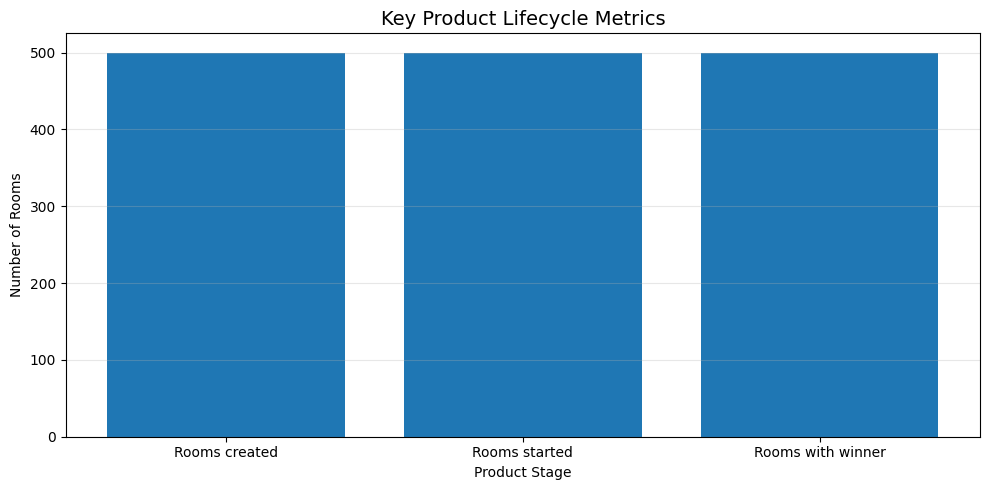

In [14]:
# Візуалізуємо основні етапи життєвого циклу кімнати

lifecycle_metrics = pd.DataFrame({
    "stage": [
        "Rooms created",
        "Rooms started",
        "Rooms with winner"
    ],
    "rooms": [
        len(created_rooms),
        len(rooms_with_started_session),
        len(rooms_with_result)
    ]
})

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    lifecycle_metrics["stage"],
    lifecycle_metrics["rooms"]
)

ax.set_title("Key Product Lifecycle Metrics", fontsize=14)
ax.set_xlabel("Product Stage")
ax.set_ylabel("Number of Rooms")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [16]:
# Визначаємо датасети створення кімнат

create_room_specs = {
    "GUEST": {
        "dataset": "02_guest_create_room",
        "creation_event": "create_room_submitted"
    },
    "AUTHENTICATED": {
        "dataset": "02_authenticated_create_room",
        "creation_event": "create_room_clicked"
    }
}

# Функція для отримання значень налаштувань кімнат

def get_room_event_values(df, event_name):

    selected = df[
        df["event_name"] == event_name
    ][["room_id", "event_value"]].dropna(
        subset=["room_id"]
    )

    return (
        selected
        .groupby("room_id")["event_value"]
        .first()
    )

# Формуємо єдину таблицю налаштувань кімнат

room_setup_frames = []

for user_type, spec in create_room_specs.items():

    df = datasets[spec["dataset"]]

    # Отримуємо кімнати, створені в сегменті

    created = df[
        df["event_name"] == spec["creation_event"]
    ]["room_id"].dropna().drop_duplicates()

    setup = pd.DataFrame({
        "room_id": created
    })

    # Отримуємо вибраний тип контенту

    content_values = get_room_event_values(
        df,
        "content_type_selected"
    )

    setup["content_type"] = (
        setup["room_id"].map(content_values)
    )

    # Отримуємо максимальну тривалість

    duration_values = get_room_event_values(
        df,
        "max_duration_selected"
    )

    setup["max_duration"] = pd.to_numeric(
        setup["room_id"].map(duration_values),
        errors="coerce"
    )

    # Отримуємо вибрані жанри

    genre_values = get_room_event_values(
        df,
        "genres_selected"
    )

    setup["genres_json"] = (
        setup["room_id"].map(genre_values)
    )

    setup["user_type"] = user_type

    room_setup_frames.append(setup)

room_setup = pd.concat(
    room_setup_frames,
    ignore_index=True
)

# Функція для обробки JSON-списків жанрів

def parse_genres(value):

    if pd.isna(value):
        return []

    try:
        parsed = json.loads(str(value))

        if isinstance(parsed, list):
            return parsed

        return []

    except (ValueError, TypeError):
        return []

# Перетворюємо JSON-значення на списки

room_setup["genres"] = (
    room_setup["genres_json"].apply(parse_genres)
)

# Рахуємо кількість жанрів у кожній кімнаті

room_setup["genre_count"] = (
    room_setup["genres"].apply(len)
)

# Перевіряємо результат

print("Кількість кімнат:", room_setup["room_id"].nunique())

print(
    "Кількість кімнат Guest:",
    room_setup.loc[
        room_setup["user_type"] == "GUEST",
        "room_id"
    ].nunique()
)

print(
    "Кількість кімнат Authenticated:",
    room_setup.loc[
        room_setup["user_type"] == "AUTHENTICATED",
        "room_id"
    ].nunique()
)

display(room_setup.head(10))

Кількість кімнат: 500
Кількість кімнат Guest: 275
Кількість кімнат Authenticated: 225


,room_id,content_type,max_duration,genres_json,user_type,genres,genre_count
0,500002,TV Shows,150,[],GUEST,[],0
1,500003,Movies,150,"[""Horror""]",GUEST,[Horror],1
2,500006,Movies,150,"[""Crime"",""Fantasy"",""Western""]",GUEST,"[Crime, Fantasy, Western]",3
3,500007,Movies,150,"[""Thriller""]",GUEST,[Thriller],1
4,500009,Movies,120,[],GUEST,[],0
5,500014,Movies,120,"[""Thriller"",""Western""]",GUEST,"[Thriller, Western]",2
6,500016,Movies,120,[],GUEST,[],0
7,500018,Movies,150,"[""Action"",""Romance""]",GUEST,"[Action, Romance]",2
8,500019,Movies,150,"[""Thriller""]",GUEST,[Thriller],1
9,500020,Movies,90,"[""Western""]",GUEST,[Western],1


In [17]:
# Аналізуємо популярність типів контенту

content_type_summary = (
    room_setup
    .dropna(subset=["content_type"])
    .groupby(["user_type", "content_type"])
    .agg(
        rooms=("room_id", "nunique")
    )
    .reset_index()
)

# Розраховуємо частку кожного типу контенту

content_type_summary["share_pct"] = (
    content_type_summary["rooms"]
    / content_type_summary
        .groupby("user_type")["rooms"]
        .transform("sum")
    * 100
)

display(content_type_summary.round(2))

,user_type,content_type,rooms,share_pct
0,AUTHENTICATED,Movies,179,79.56
1,AUTHENTICATED,TV Shows,46,20.44
2,GUEST,Movies,214,77.82
3,GUEST,TV Shows,61,22.18


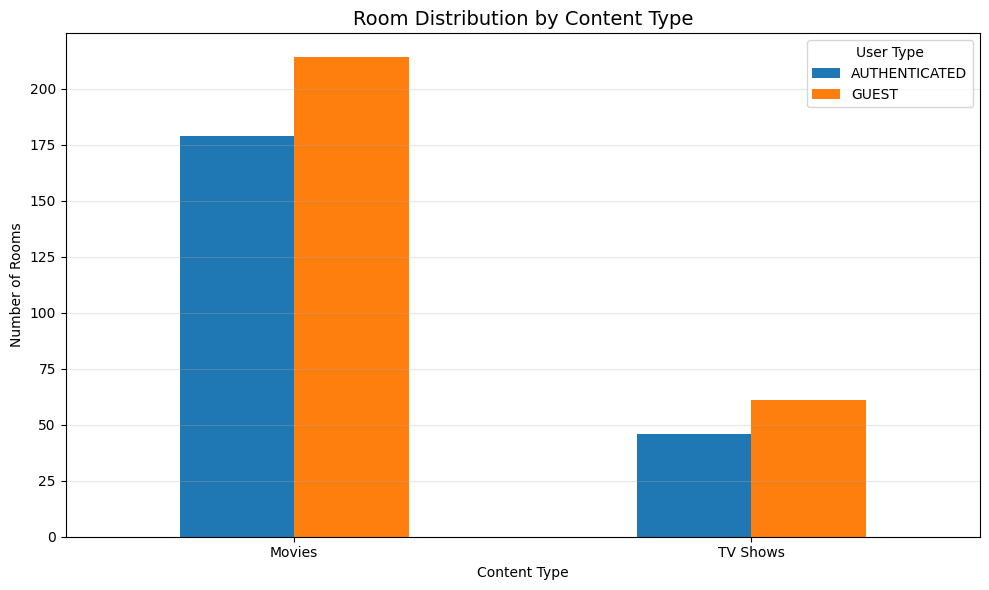

In [18]:
# Готуємо дані для візуалізації

content_pivot = (
    content_type_summary
    .pivot(
        index="content_type",
        columns="user_type",
        values="rooms"
    )
    .fillna(0)
)

# Візуалізуємо кількість кімнат за типом контенту

fig, ax = plt.subplots(figsize=(10, 6))

content_pivot.plot(
    kind="bar",
    ax=ax
)

ax.set_title("Room Distribution by Content Type", fontsize=14)
ax.set_xlabel("Content Type")
ax.set_ylabel("Number of Rooms")
ax.legend(title="User Type")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [19]:
# Аналізуємо вибрану максимальну тривалість

duration_summary = (
    room_setup
    .dropna(subset=["max_duration"])
    .groupby(["user_type", "max_duration"])
    .agg(
        rooms=("room_id", "nunique")
    )
    .reset_index()
)

# Розраховуємо частку кожного значення тривалості

duration_summary["share_pct"] = (
    duration_summary["rooms"]
    / duration_summary
        .groupby("user_type")["rooms"]
        .transform("sum")
    * 100
)

duration_summary = duration_summary.sort_values(
    ["user_type", "max_duration"]
)

display(duration_summary.round(2))

,user_type,max_duration,rooms,share_pct
0,AUTHENTICATED,90,78,34.67
1,AUTHENTICATED,120,79,35.11
2,AUTHENTICATED,150,68,30.22
3,GUEST,90,90,32.73
4,GUEST,120,90,32.73
5,GUEST,150,95,34.55


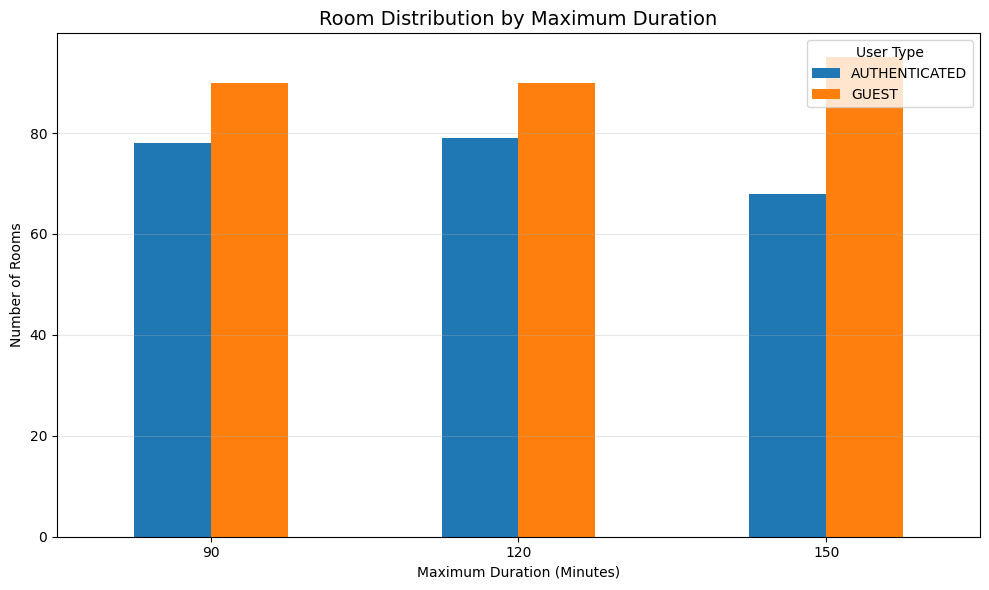

In [20]:
# Готуємо дані для візуалізації

duration_pivot = (
    duration_summary
    .pivot(
        index="max_duration",
        columns="user_type",
        values="rooms"
    )
    .fillna(0)
    .sort_index()
)

# Візуалізуємо розподіл тривалості

fig, ax = plt.subplots(figsize=(10, 6))

duration_pivot.plot(
    kind="bar",
    ax=ax
)

ax.set_title("Room Distribution by Maximum Duration", fontsize=14)
ax.set_xlabel("Maximum Duration (Minutes)")
ax.set_ylabel("Number of Rooms")
ax.legend(title="User Type")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [21]:
# Розгортаємо списки жанрів у окремі записи

genres_data = room_setup[
    ["user_type", "room_id", "genres"]
].explode("genres")

genres_data = genres_data.dropna(
    subset=["genres"]
)

# Видаляємо можливі повтори жанрів у межах однієї кімнати

genres_data = genres_data.drop_duplicates(
    ["user_type", "room_id", "genres"]
)

# Розраховуємо популярність жанрів

genre_summary = (
    genres_data
    .groupby(["user_type", "genres"])
    .agg(
        rooms=("room_id", "nunique")
    )
    .reset_index()
    .rename(columns={"genres": "genre"})
)

# Визначаємо кількість кімнат у кожному сегменті

rooms_by_user = (
    room_setup
    .groupby("user_type")["room_id"]
    .nunique()
)

# Розраховуємо частку кімнат із відповідним жанром

genre_summary["share_of_rooms_pct"] = (
    genre_summary["rooms"]
    / genre_summary["user_type"].map(rooms_by_user)
    * 100
)

# Визначаємо 10 найпопулярніших жанрів

top_genres = (
    genre_summary
    .groupby("genre")["rooms"]
    .sum()
    .nlargest(10)
    .index
)

top_genres_summary = genre_summary[
    genre_summary["genre"].isin(top_genres)
].copy()

display(
    top_genres_summary
    .sort_values(["user_type", "rooms"], ascending=[True, False])
    .round(2)
)

,user_type,genre,rooms,share_of_rooms_pct
17,AUTHENTICATED,Western,23,10.22
9,AUTHENTICATED,History,20,8.89
12,AUTHENTICATED,Mystery,20,8.89
5,AUTHENTICATED,Documentary,19,8.44
3,AUTHENTICATED,Comedy,18,8.00
11,AUTHENTICATED,Music,17,7.56
6,AUTHENTICATED,Drama,15,6.67
2,AUTHENTICATED,Animation,14,6.22
10,AUTHENTICATED,Horror,12,5.33
14,AUTHENTICATED,Science Fiction,12,5.33


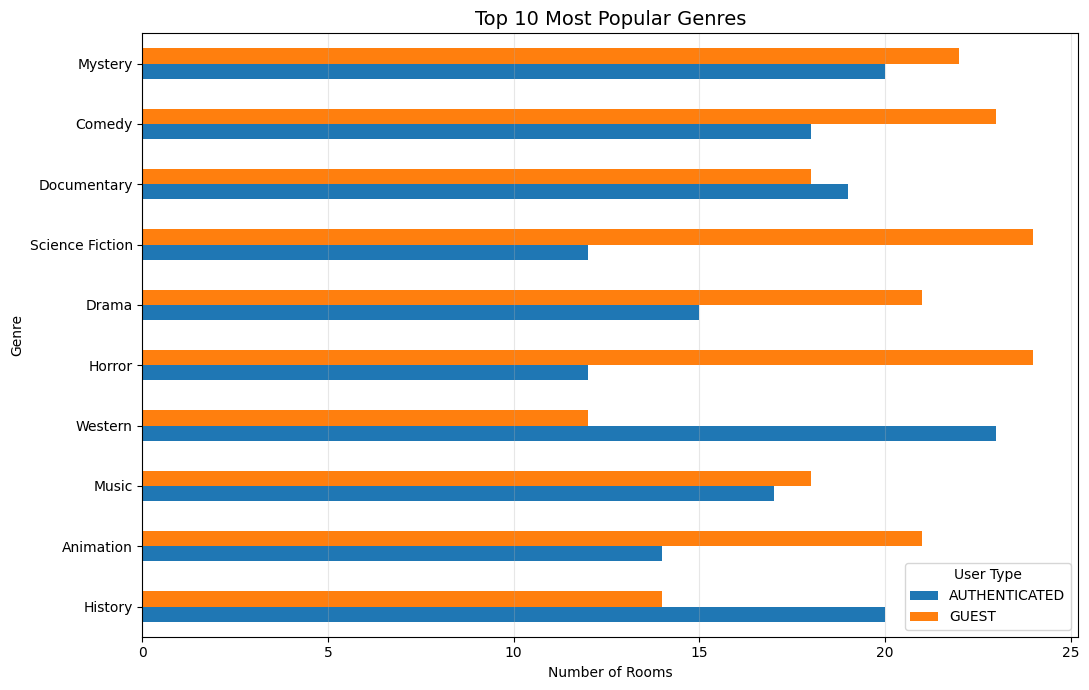

In [22]:
# Формуємо таблицю для візуалізації популярності жанрів

genre_pivot = (
    top_genres_summary
    .pivot(
        index="genre",
        columns="user_type",
        values="rooms"
    )
    .fillna(0)
)

genre_pivot["total"] = genre_pivot.sum(axis=1)

genre_pivot = (
    genre_pivot
    .sort_values("total", ascending=True)
    .drop(columns="total")
)

# Візуалізуємо популярність жанрів

fig, ax = plt.subplots(figsize=(11, 7))

genre_pivot.plot(
    kind="barh",
    ax=ax
)

ax.set_title("Top 10 Most Popular Genres", fontsize=14)
ax.set_xlabel("Number of Rooms")
ax.set_ylabel("Genre")
ax.legend(title="User Type")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [23]:
# Аналізуємо кількість вибраних жанрів на одну кімнату

genre_selection_summary = (
    room_setup
    .groupby("user_type")
    .agg(
        total_rooms=("room_id", "nunique"),
        rooms_without_genres=(
            "genre_count",
            lambda x: (x == 0).sum()
        ),
        avg_genres_per_room=("genre_count", "mean"),
        median_genres_per_room=("genre_count", "median"),
        max_genres_per_room=("genre_count", "max")
    )
    .reset_index()
)

# Розраховуємо частку кімнат без жанрів

genre_selection_summary["empty_genres_pct"] = (
    genre_selection_summary["rooms_without_genres"]
    / genre_selection_summary["total_rooms"]
    * 100
)

display(genre_selection_summary.round(2))

,user_type,total_rooms,rooms_without_genres,avg_genres_per_room,median_genres_per_room,max_genres_per_room,empty_genres_pct
0,AUTHENTICATED,225,53,1.18,1.0,3,23.56
1,GUEST,275,59,1.21,1.0,3,21.45


In [24]:
# Визначаємо датасети сторінок результатів

results_specs = {
    "GUEST": "08_guest_results_winners",
    "AUTHENTICATED": "08_authenticated_results_winners"
}

# Визначаємо досліджувані функції

result_actions = [
    "winner_details_clicked",
    "another_round_clicked",
    "explore_taste_clicked",
    "view_sessions_clicked"
]

result_engagement = []

for user_type, dataset_name in results_specs.items():

    page_df = all_events[
        all_events["dataset"] == dataset_name
    ].copy()

    # Визначаємо загальну кількість відвідувачів сторінки

    page_visitors = page_df["visitor_id"].nunique()

    for action in result_actions:

        action_df = page_df[
            (page_df["event_name"] == action) &
            (page_df["event_value_bool"] == True)
        ]

        action_events = len(action_df)

        action_visitors = (
            action_df["visitor_id"].nunique()
        )

        result_engagement.append({
            "user_type": user_type,
            "action": action,
            "page_visitors": page_visitors,
            "action_events": action_events,
            "unique_action_visitors": action_visitors,
            "adoption_rate_pct": calculate_percentage(
                action_visitors,
                page_visitors
            )
        })

result_engagement_summary = pd.DataFrame(
    result_engagement
)

display(
    result_engagement_summary
    .sort_values(
        ["user_type", "adoption_rate_pct"],
        ascending=[True, False]
    )
    .round(2)
)

,user_type,action,page_visitors,action_events,unique_action_visitors,adoption_rate_pct
4,AUTHENTICATED,winner_details_clicked,373,198,162,43.43
7,AUTHENTICATED,view_sessions_clicked,373,162,146,39.14
6,AUTHENTICATED,explore_taste_clicked,373,164,138,37.00
5,AUTHENTICATED,another_round_clicked,373,78,68,18.23
0,GUEST,winner_details_clicked,965,219,219,22.69
1,GUEST,another_round_clicked,965,80,80,8.29
2,GUEST,explore_taste_clicked,965,0,0,0.00
3,GUEST,view_sessions_clicked,965,0,0,0.00


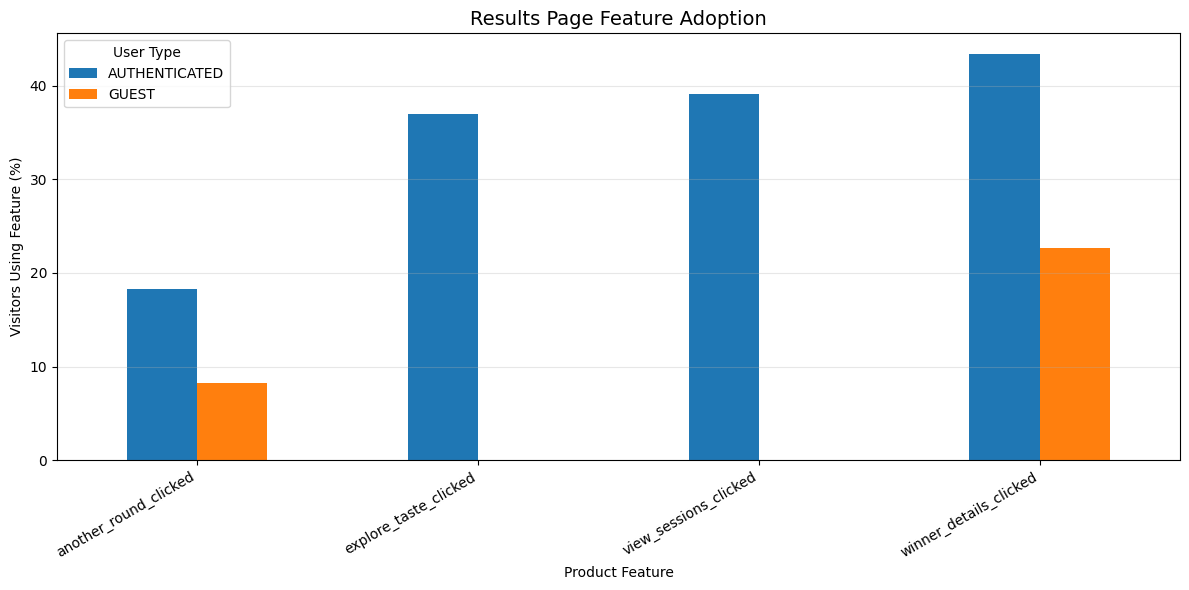

In [25]:
# Готуємо таблицю для порівняння використання функцій

engagement_pivot = (
    result_engagement_summary
    .pivot(
        index="action",
        columns="user_type",
        values="adoption_rate_pct"
    )
    .fillna(0)
)

# Візуалізуємо частку відвідувачів, які використовували функції

fig, ax = plt.subplots(figsize=(12, 6))

engagement_pivot.plot(
    kind="bar",
    ax=ax
)

ax.set_title("Results Page Feature Adoption", fontsize=14)
ax.set_xlabel("Product Feature")
ax.set_ylabel("Visitors Using Feature (%)")
ax.legend(title="User Type")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


In [26]:
# Визначаємо датасети сторінок запрошення друзів

invitation_specs = {
    "GUEST": "03_guest_host_room_invite_friends",
    "AUTHENTICATED": "03_authenticated_host_room_invite_friends"
}

# Визначаємо способи запрошення

invitation_actions = [
    "room_invite_link_copied",
    "room_invite_telegram_clicked"
]

invitation_results = []

for user_type, dataset_name in invitation_specs.items():

    page_df = all_events[
        all_events["dataset"] == dataset_name
    ].copy()

    total_rooms = page_df["room_id"].nunique()

    for action in invitation_actions:

        action_df = page_df[
            (page_df["event_name"] == action) &
            (page_df["event_value_bool"] == True)
        ]

        action_rooms = action_df["room_id"].nunique()

        invitation_results.append({
            "user_type": user_type,
            "invitation_method": action,
            "total_rooms": total_rooms,
            "rooms_using_feature": action_rooms,
            "adoption_rate_pct": calculate_percentage(
                action_rooms,
                total_rooms
            )
        })

invitation_summary = pd.DataFrame(
    invitation_results
)

display(
    invitation_summary.round(2)
)

,user_type,invitation_method,total_rooms,rooms_using_feature,adoption_rate_pct
0,GUEST,room_invite_link_copied,275,198,72.00
1,GUEST,room_invite_telegram_clicked,275,46,16.73
2,AUTHENTICATED,room_invite_link_copied,225,173,76.89
3,AUTHENTICATED,room_invite_telegram_clicked,225,43,19.11


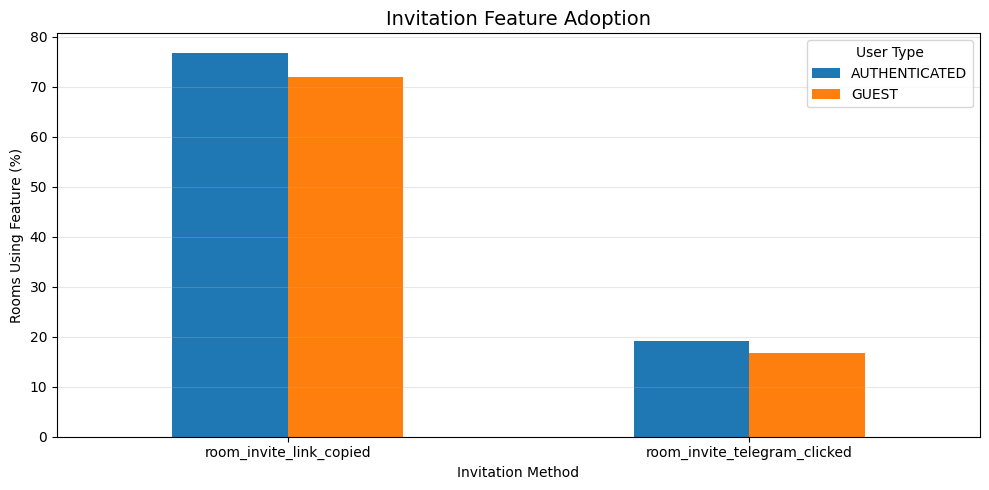

In [27]:
# Формуємо таблицю для візуалізації

invitation_pivot = (
    invitation_summary
    .pivot(
        index="invitation_method",
        columns="user_type",
        values="adoption_rate_pct"
    )
    .fillna(0)
)

# Візуалізуємо використання способів запрошення

fig, ax = plt.subplots(figsize=(10, 5))

invitation_pivot.plot(
    kind="bar",
    ax=ax
)

ax.set_title("Invitation Feature Adoption", fontsize=14)
ax.set_xlabel("Invitation Method")
ax.set_ylabel("Rooms Using Feature (%)")
ax.legend(title="User Type")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [28]:
# Отримуємо час створення кожної кімнати

room_created = (
    room_creation_events
    .groupby("room_id")
    .agg(
        created_at=("event_timestamp", "min"),
        user_type=("user_type", "first")
    )
    .reset_index()
)

# Отримуємо час завершення голосування останнім учасником

room_completed = (
    activity_df[
        activity_df["dataset"].isin(swipe_datasets) &
        (activity_df["event_name"] == "swipe_session_completed") &
        (activity_df["room_id"].notna())
    ]
    .groupby("room_id")
    .agg(
        completed_at=("event_timestamp", "max")
    )
    .reset_index()
)

# Об'єднуємо дані про створення та завершення кімнат

room_lifecycle = room_created.merge(
    room_completed,
    on="room_id",
    how="left",
    validate="one_to_one"
)

# Розраховуємо тривалість життєвого циклу кімнати

room_lifecycle["duration_minutes"] = (
    room_lifecycle["completed_at"]
    - room_lifecycle["created_at"]
).dt.total_seconds() / 60

# Перевіряємо якість результату

print("Усього створених кімнат:", len(room_lifecycle))

print(
    "Кімнат із подією завершення:",
    room_lifecycle["completed_at"].notna().sum()
)

print(
    "Кімнат без події завершення:",
    room_lifecycle["completed_at"].isna().sum()
)

print(
    "Кімнат із від'ємною тривалістю:",
    (room_lifecycle["duration_minutes"] < 0).sum()
)

# Відбираємо коректні значення тривалості

room_lifecycle_valid = room_lifecycle[
    room_lifecycle["duration_minutes"].notna() &
    (room_lifecycle["duration_minutes"] >= 0)
].copy()

display(room_lifecycle_valid.head(10))

Усього створених кімнат: 500
Кімнат із подією завершення: 500
Кімнат без події завершення: 0
Кімнат із від'ємною тривалістю: 0


,room_id,created_at,user_type,completed_at,duration_minutes
0,500001,2026-10-21 18:52:02+00:00,AUTHENTICATED,2026-10-21 19:35:55+00:00,43.883333
1,500002,2026-09-06 13:52:17+00:00,GUEST,2026-09-06 14:41:36+00:00,49.316667
2,500003,2026-10-28 17:32:21+00:00,GUEST,2026-10-28 18:16:08+00:00,43.783333
3,500004,2026-09-15 14:11:08+00:00,AUTHENTICATED,2026-09-15 15:07:36+00:00,56.466667
4,500005,2026-10-03 10:14:30+00:00,AUTHENTICATED,2026-10-03 10:44:38+00:00,30.133333
5,500006,2026-10-16 09:52:17+00:00,GUEST,2026-10-16 10:30:07+00:00,37.833333
6,500007,2026-10-22 19:01:44+00:00,GUEST,2026-10-22 19:39:29+00:00,37.750000
7,500008,2026-10-03 12:47:36+00:00,AUTHENTICATED,2026-10-03 13:39:27+00:00,51.850000
8,500009,2026-09-24 14:36:51+00:00,GUEST,2026-09-24 15:28:25+00:00,51.566667
9,500010,2026-10-29 13:03:48+00:00,AUTHENTICATED,2026-10-29 13:57:00+00:00,53.200000


In [29]:
# Розраховуємо загальну статистику тривалості

room_duration_summary = (
    room_lifecycle_valid
    .groupby("user_type")
    .agg(
        rooms=("room_id", "nunique"),
        avg_duration_min=("duration_minutes", "mean"),
        median_duration_min=("duration_minutes", "median"),
        min_duration_min=("duration_minutes", "min"),
        q25=("duration_minutes", lambda x: x.quantile(0.25)),
        q75=("duration_minutes", lambda x: x.quantile(0.75)),
        max_duration_min=("duration_minutes", "max")
    )
    .reset_index()
)

display(room_duration_summary.round(2))

,user_type,rooms,avg_duration_min,median_duration_min,min_duration_min,q25,q75,max_duration_min
0,AUTHENTICATED,225,47.16,48.57,29.38,41.02,53.25,61.42
1,GUEST,275,46.85,46.98,29.30,40.26,53.41,64.23


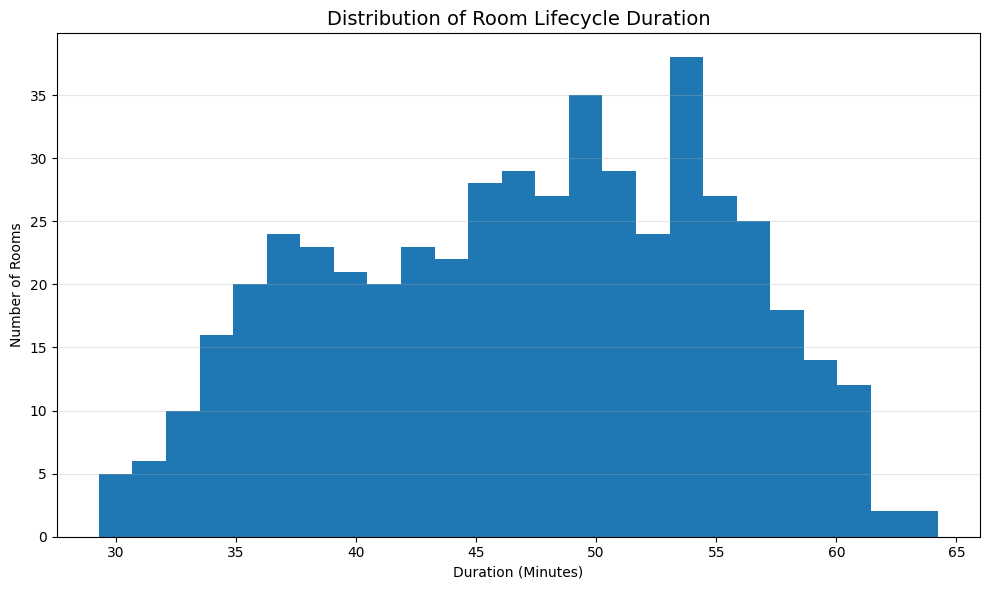

In [30]:
# Візуалізуємо розподіл тривалості життєвого циклу кімнат

fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(
    room_lifecycle_valid["duration_minutes"],
    bins=25
)

ax.set_title("Distribution of Room Lifecycle Duration", fontsize=14)
ax.set_xlabel("Duration (Minutes)")
ax.set_ylabel("Number of Rooms")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [31]:
# Формуємо підсумкову таблицю продуктових показників

product_metrics_summary = product_kpi[
    ["metric", "value", "unit"]
].copy()

# Додаємо показники використання налаштувань кімнат

configuration_metrics = pd.DataFrame([
    {
        "metric": "Rooms with content type selected",
        "value": room_setup["content_type"].notna().sum(),
        "unit": "rooms"
    },
    {
        "metric": "Rooms with duration selected",
        "value": room_setup["max_duration"].notna().sum(),
        "unit": "rooms"
    },
    {
        "metric": "Rooms with genres selected",
        "value": (room_setup["genre_count"] > 0).sum(),
        "unit": "rooms"
    }
])

# Додаємо тривалість життєвого циклу

lifecycle_metrics = pd.DataFrame([
    {
        "metric": "Rooms with valid lifecycle duration",
        "value": len(room_lifecycle_valid),
        "unit": "rooms"
    },
    {
        "metric": "Average room lifecycle duration",
        "value": room_lifecycle_valid["duration_minutes"].mean(),
        "unit": "minutes"
    },
    {
        "metric": "Median room lifecycle duration",
        "value": room_lifecycle_valid["duration_minutes"].median(),
        "unit": "minutes"
    }
])

# Об'єднуємо всі показники

product_metrics_summary = pd.concat(
    [
        product_metrics_summary,
        configuration_metrics,
        lifecycle_metrics
    ],
    ignore_index=True
)

display(product_metrics_summary.round(2))

,metric,value,unit
0,Total actual events,47657.00,events
1,Unique visitors,2016.00,visitors
2,Authenticated users,543.00,users
3,Rooms created,500.00,rooms
4,Rooms started,500.00,rooms
5,Room start rate,100.00,%
6,Participant sessions started,1700.00,sessions
7,Participant sessions completed,1700.00,sessions
8,Participant session completion rate,100.00,%
9,Rooms with winner,499.00,rooms
